In [28]:
#%matplotlib notebook
#%matplotlib widget
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import os
singlecol = 3.5
plt.rcParams.update({'font.size': 8})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
#plt.rcParams['font.family'] = 'dejavu'
plt.rcParams.update({'lines.linewidth':0.5})
plt.rcParams.update({'axes.linewidth':0.5})
plt.rcParams.update({'lines.markersize':2})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 7})

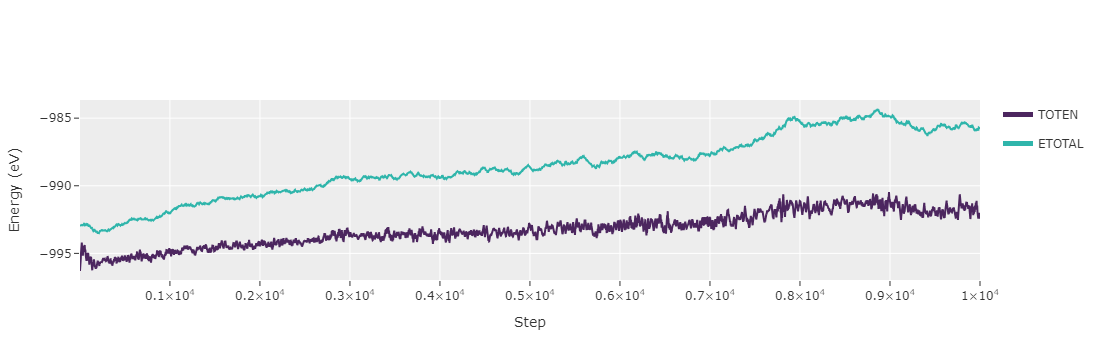

In [2]:
import py4vasp                       
mycalc = py4vasp.Calculation.from_path( "." )
mycalc.energy[:].plot( "TOTEN, ETOTAL" )

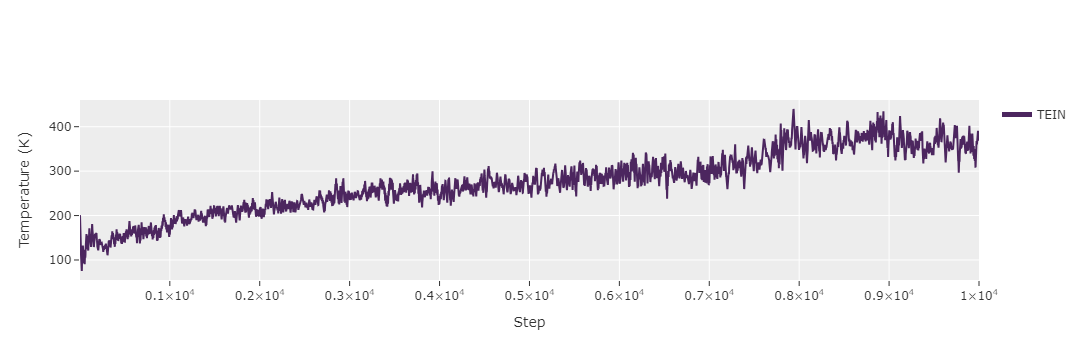

In [3]:
mycalc.energy[:].plot("TEIN")

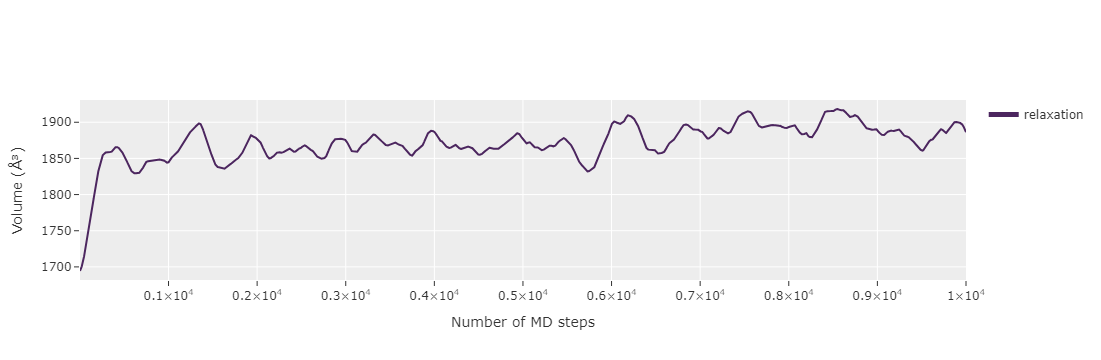

In [4]:
! cat ./REPORT | grep "mc> LV" > ./monitored_cell_volume.dat
from py4vasp import plot
import numpy as np

volume = np.loadtxt("./monitored_cell_volume.dat", usecols=2)

# plot the volume
plot(np.arange(len(volume))+1, volume, "relaxation", xlabel="Number of MD steps", ylabel="Volume (Å³)")

In [5]:
PCF = mycalc.pair_correlation[:].to_dict()

Text(0.5, 1.0, 'Pair Correlation Function')

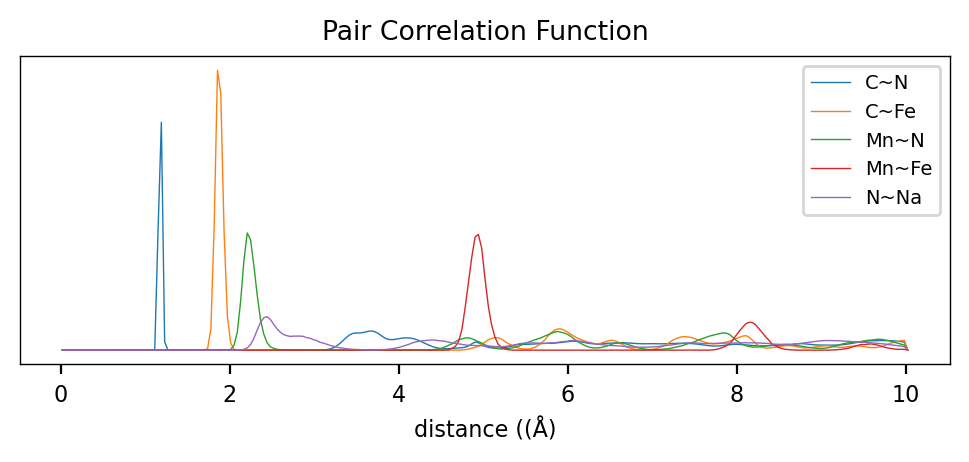

In [33]:
plt.figure(figsize = (6,2), dpi=200)
label_list=['C~N','C~Fe','Mn~N','Mn~Fe','N~Na']
for i in range(len(label_list)):
    plt.plot(PCF['distances'], PCF[label_list[i]][0], label=label_list[i])
plt.xlabel('distance (Å)')
plt.yticks([])
plt.legend()
plt.title('Pair Correlation Function')

In [73]:
! grep ERR ML_LOGFILE > err.dat
t1, ERR = np.loadtxt("./err.dat", usecols=[1,3], unpack=True)

! grep BEEF ML_LOGFILE > beef.dat
t2, BEEF, CTIFOR = np.loadtxt("./beef.dat", usecols=[1,3,5], unpack=True)

! grep "STATUS" ML_LOGFILE|grep -E 'learning|critical'|grep -v "#" >status.dat
when_train = np.loadtxt("./status.dat", usecols=1)

! grep mag OSZICAR > cfg.dat
when_FP = np.loadtxt("./cfg.dat", usecols=0)

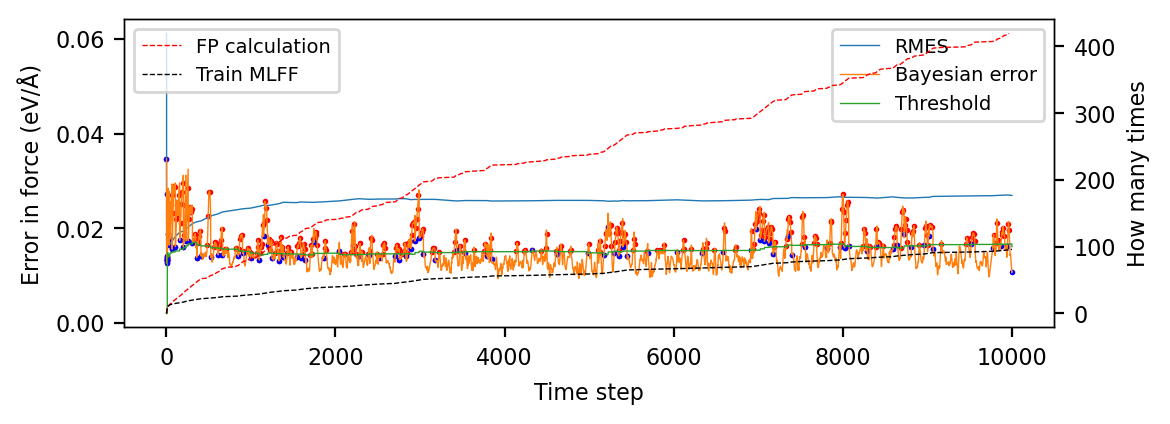

In [83]:
#plt.figure(figsize = (6,2), dpi=200)
fig, ax1 = plt.subplots(figsize = (6,2), dpi=200)
ax1.plot(t1, ERR, label='RMES')
ax1.plot(t2, BEEF, label='Bayesian error')
ax1.plot(t2, CTIFOR, label='Threshold')
for i in range(when_FP.shape[0]):
    ax1.scatter(when_FP[i], BEEF[int(when_FP[i])-1], color='r', s=1)
for i in range(when_train.shape[0]):
    ax1.scatter(when_train[i], BEEF[int(when_train[i])-1], color='blue', s=1)
ax1.legend()
ax1.set_xlabel("Time step")
ax1.set_ylabel("Error in force (eV/Å)")

ax2 = ax1.twinx()
ax2.plot(when_FP, range(when_FP.shape[0]), '--', label='FP calculation', color='red')
ax2.plot(when_train, range(when_train.shape[0]), '--', label='Train MLFF', color='black')
ax2.set_ylabel('How many times')
ax2.legend()

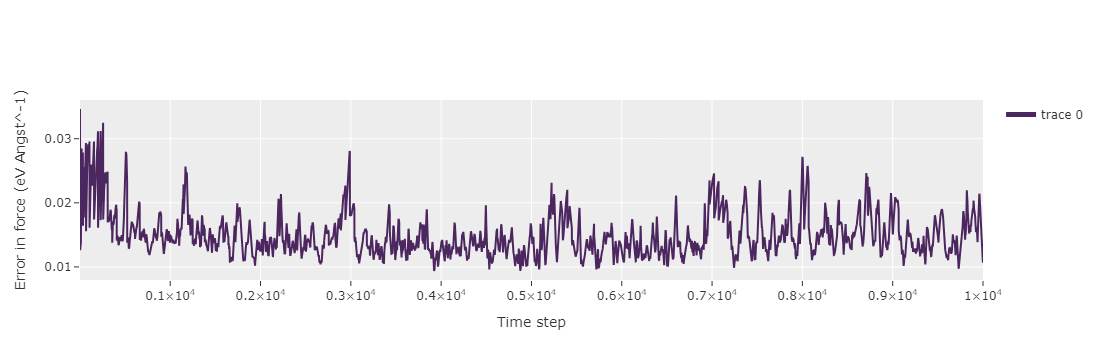

In [39]:
plot(t2, CTIFOR, xlabel="Time step", ylabel="Error in force (eV Angst^-1)")
plot(t2, BEEF, xlabel="Time step", ylabel="Error in force (eV Angst^-1)")
#plot(t1, ERR, xlabel="Time step", ylabel="Bayesian error")

In [40]:
from py4vasp import MLFFErrorAnalysis
# Compute the errors
mlff_error_analysis = MLFFErrorAnalysis.from_files(
   dft_data="./*.h5",
   mlff_data="./*.h5"
 )
energy_error = mlff_error_analysis.get_energy_error_per_atom()
# force_error = mlff_error_analysis.get_force_rmse()
# stress_error = mlff_error_analysis.get_stress_rmse()
x = np.arange(len(energy_error))
plot(x, energy_error, ylabel="Energy error [eV/atom]", xlabel="Configuration Number")

KeyError: 'free energy    TOTEN'

In [84]:
when_train.shape, t1.shape

((97,), (96,))

In [80]:
BEEF[int(when_train[i])]

IndexError: index 10000 is out of bounds for axis 0 with size 10000

In [52]:
range(when_train.shape[0])

TypeError: 'tuple' object cannot be interpreted as an integer